# create deep agent와 도구

**이 노트북에서 할 일**

1. 자료실 규정을 찾는 도구 하나를 만들어 Deep Agent에 더하고, 조립을 모델 없이 봅니다.
2. 그래프에 등록된 도구와 모델에게 가는 도구 목록이 어떻게 다른지, 백엔드와 함께 봅니다.
3. 호출 한도를 두 곳에 준 Deep Agent를 실제 모델로 한 번 실행하고, 도구 선택과 요청 수를 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 6절에서 Deep Agent를 한 번 실행합니다.
모델이 우리 도구를 한 번 부르고 답하면, 모델 요청은 2번입니다.
바깥 호출 한도 3과 서브에이전트 호출 한도 2를 주어, 요청이 끝없이 늘지 않게 막습니다.
요금표로 어림한 예상 비용은 0.004달러 아래이고, 청구 금액이 아닙니다.

모델이 고르는 도구와 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.
읽거나 쓰는 파일은 없습니다.
앞에서 배운 함수 여섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 deepagents 0.7.0과 langchain 1.4.0입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
우리 도구가 기본 도구에 더해지고, 모델에게 가는 목록에서 `execute`가 빠지는 까닭을 보는 자리입니다.
5~7절은 실제 모델로 실행하고 요청 수를 세는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 교재용 규정 글 넷에서 파란 상자 도구 lookup_rule로, 거기서 파란 상자 create_deep_agent 인자 tools에 lookup_rule 하나로 화살표가 갑니다. 그 아래 노란 상자 그래프에 등록된 도구 열 기본 아홉과 lookup_rule로 화살표가 갑니다. 그 옆에 노란 상자 기본 백엔드 StateBackend 명령을 실행할 수 있는가 False가 있습니다. 두 노란 상자에서 맨 아래 노란 상자 모델이 받은 도구 아홉 execute만 빠짐으로 화살표가 가는 그림](attachment:02-1-우리-도구가-더해진-조립.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 정한 글이고, 파란 상자는 우리가 만든 도구와 부른 함수입니다.
노란 상자는 노트북 출력으로 확인한 값이고, 맨 아래 상자는 6절 기록 훅의 출력입니다.
오른쪽 노란 상자의 백엔드가 명령을 실행하지 못해서, 모델이 받는 목록에서 execute가 빠집니다.
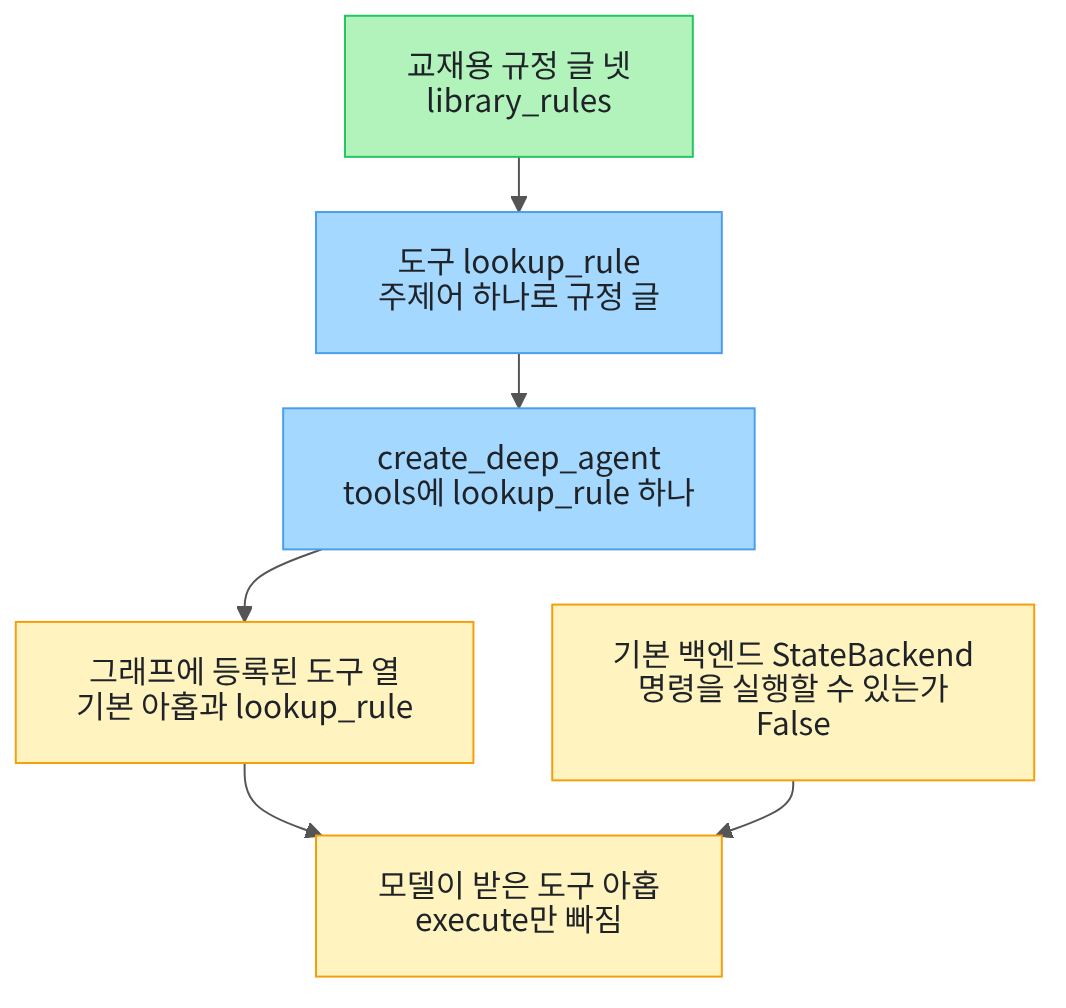

## 1. 준비

이 절에서는 01절에서 조립만 본 Deep Agent에 우리 도구를 더하고, 실제 모델로 실행합니다.
절 제목의 create deep agent는 함수 `create_deep_agent`의 이름을 띄어 쓴 것입니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langchain: 1.4.0`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
백엔드 이름 둘과 함수 `supports_execution`은 이 절에서 처음 쓰고, 뜻은 3·4절에서 풉니다.
함수 `wrap_model_call`은 Ch 22 02절, 미들웨어 `ModelCallLimitMiddleware`는 Ch 22 04절에서 썼습니다.
마지막 가져오기 줄은 앞에서 배운 함수 여섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·백엔드(이 절 처음)·미들웨어(Ch 22)·모델(Ch 6 01절)·메시지(Ch 13 04절)·도구(Ch 19 01절) 이름을 가져옵니다
from deepagents import create_deep_agent
from deepagents.backends import LocalShellBackend, StateBackend
from deepagents.middleware.filesystem import supports_execution
from langchain.agents.middleware import ModelCallLimitMiddleware, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
# 앞 챕터와 01절에서 배운 함수 여섯은 도구 파일에서 가져옵니다
from harness_tools import estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names")

도구 파일에서 가져온 함수: estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, names_only_in, show_messages, sum_usage, tool_call_names, tool_names`가 보입니다.
Ch 19 06절 함수 `show_messages`는 메시지 목록을 한 줄씩 출력합니다.
Ch 19 04절 함수 `tool_call_names`는 응답 하나에 든 도구 요청의 이름을 모읍니다.
Ch 19 05절 함수 `sum_usage`는 목록 안 응답마다 요청 하나로 세고 토큰을 더합니다.
Ch 6 06절 함수 `estimate_cost`는 사용량과 요금표로 예상 비용을 셉니다.

함수 `tool_names`와 `names_only_in`은 01절 3절에서 만든 함수입니다.
앞의 함수는 에이전트 그래프의 도구 이름을, 뒤의 함수는 둘째 목록에만 있는 이름을 모읍니다.

앞에서 배운 함수는 `harness_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 6절 실행 셀에서만 나갑니다.

01절에서 본 것처럼, 함수 `create_deep_agent`에는 이 모델 객체를 그대로 넘깁니다.
모델 이름 글자만 넘기면 temperature 설정이 없는 모델을 새로 만들기 때문입니다.

## 2. 자료실 규정 도구 만들기

Ch 21 01절에서는 교육센터 자료실 규정 셋을 딕셔너리에 담고, 주제어로 찾는 도구를 만들었습니다.
이 절도 같은 규정 글을 쓰고, Ch 26 01절 규정 글의 연장 두 문장을 더합니다.
이 글은 교재용으로 만든 규정이고, 실제 도서관 규정이 아닙니다.
실행 전에 정한 글이고, 결과를 보고 바꾸지 않았습니다.

In [5]:
# 도구가 찾을 교재용 규정 글 넷을 주제어마다 정합니다(실제 도서관 규정이 아님)
library_rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "연장": "반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제어:", list(library_rules))

규정 주제어: ['대출', '연장', '연체', '운영']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '연장', '연체', '운영']`이 보입니다.
대출·연체·운영 글은 Ch 21 01절 규정 글과 같고, 연장 글은 Ch 26 01절 규정 글의 두 문장입니다.

다음 셀은 이 딕셔너리에서 주제어 하나로 규정 글을 찾는 도구를 만듭니다.
함수 위의 `@tool` 줄은 데코레이터 줄입니다.
데코레이터 줄은 함수 위에 붙여 그 함수를 다른 것으로 감싸는 표시이고, 뜻은 Ch 2 09절에 있습니다.
이 셀에서는 이 줄이 아래 함수를 도구로 등록합니다.
Ch 19 01절처럼 매개변수 `topic: str`은 모델이 채울 인자가 되고, 독스트링은 도구 설명이 됩니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_rule(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다."""
    # 없는 주제어면 오류 대신 정해 둔 안내 글을 내놓습니다
    if topic in library_rules:
        return library_rules[topic]
    return "그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Ch 21 01절 도구 `lookup_policy`는 없는 주제어에 오류를 냈습니다.
이 도구는 오류 대신 넣을 수 있는 주제어를 알려 주는 글을 내놓습니다.
모델은 그 글을 보고 주제어를 다시 고를 수 있습니다.
도구 함수는 우리가 쓰는 평범한 Python 함수라서, 정해 둔 글을 내놓아도 됩니다.

다음 셀은 모델이 보게 될 도구 이름과 설명과 인자를 봅니다.

In [7]:
# 모델이 보게 될 도구 이름·설명·인자를 봅니다
print("도구 이름:", lookup_rule.name)
print("도구 설명:", lookup_rule.description)
print("인자:", lookup_rule.args)

도구 이름: lookup_rule
도구 설명: 교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다.
인자: {'topic': {'title': 'Topic', 'type': 'string'}}


**결과 읽기** — 출력 줄 `도구 이름: lookup_rule`과 `인자: {'topic': {'title': 'Topic', 'type': 'string'}}`이 보입니다.
도구 설명 줄은 함수의 독스트링과 같은 글입니다.
모델은 이 설명을 읽고, 인자 `topic`에 넣을 주제어를 스스로 고릅니다.

다음 셀은 모델 없이 도구만 두 번 실행합니다.
Ch 19 05절처럼 도구의 `invoke`에 인자 딕셔너리를 넘기면, 모델을 거치지 않고 함수가 실행됩니다.

In [8]:
# 모델 없이 도구만, 있는 주제어와 없는 주제어로 한 번씩 실행합니다(Ch 19 05절 도구.invoke)
print("연장으로 부른 결과:", lookup_rule.invoke({"topic": "연장"}))
print("주차로 부른 결과:", lookup_rule.invoke({"topic": "주차"}))

연장으로 부른 결과: 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.
주차로 부른 결과: 그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요.


**결과 읽기** — 라벨 `연장으로 부른 결과:` 뒤에 연장 규정 두 문장이 보입니다.
라벨 `주차로 부른 결과:` 뒤에는 넣을 수 있는 주제어를 알려 주는 정해 둔 글이 보입니다.
같은 인자를 넣으면 늘 같은 글이 나오는 도구입니다.

## 3. 우리 도구를 더한 조립 보기

01절에서는 인자 없이 만든 Deep Agent의 도구 아홉을 보았습니다.
이번에는 인자 `tools=`에 우리 도구를 넘겨 만들고, 기준과 견줍니다.
먼저 기준이 될 Deep Agent를 01절처럼 만듭니다.

In [9]:
# 01절처럼 인자 없이 Deep Agent를 만들어, 견줄 기준 도구 목록을 얻습니다(요청은 보내지 않음)
base_agent = create_deep_agent(model=model)
base_tools = tool_names(base_agent)
print("기본 도구 수:", len(base_tools))

기본 도구 수: 9


**결과 읽기** — 출력 줄 `기본 도구 수: 9`가 보입니다.
01절 3절과 같은 수이고, 이 목록 `base_tools`가 이 절의 기준입니다.

실행 전에 예상해 봅니다.
우리 도구를 넘기면 기본 도구 아홉은 그대로 남을까요, 아니면 우리 도구로 바뀔까요?

In [10]:
# 인자 tools=에 우리 도구 하나를 넘겨 만들고, 도구 수와 이름을 봅니다(요청은 보내지 않음)
tool_agent = create_deep_agent(model=model, tools=[lookup_rule])
tool_list = tool_names(tool_agent)
print("도구 수:", len(tool_list))
print("도구 이름:", tool_list)

도구 수: 10
도구 이름: ['delete', 'edit_file', 'execute', 'glob', 'grep', 'lookup_rule', 'ls', 'read_file', 'task', 'write_file']


**결과 읽기** — 출력 줄 `도구 수: 10`이 보입니다.
라벨 `도구 이름:` 뒤의 목록에 `'lookup_rule'`이 알파벳 차례 자리에 끼어 있습니다.
설치판 `graph.py` 336행 독스트링도 넘긴 도구는 더해지기만 하고, 기본 도구를 빼지 않는다고 적습니다.

다음 셀은 01절 함수 `names_only_in`으로 두 목록의 차이를 양쪽으로 봅니다.

In [11]:
# 기준 목록과 견주어 더해진 도구와 빠진 도구를 봅니다(01절 함수 names_only_in)
added_tools = names_only_in(base_tools, tool_list)
removed_tools = names_only_in(tool_list, base_tools)
print("더해진 도구:", added_tools)
print("빠진 도구:", removed_tools)

더해진 도구: ['lookup_rule']
빠진 도구: []


**결과 읽기** — 출력 줄 `더해진 도구: ['lookup_rule']`과 `빠진 도구: []`가 보입니다.
기본 도구 아홉은 모두 남았고, 우리 도구 하나만 더해졌습니다.

다음 셀은 두 Deep Agent의 노드 이름을 견줍니다.

In [12]:
# 두 Deep Agent의 노드 이름이 같은지 봅니다
base_graph = base_agent.get_graph()
tool_graph = tool_agent.get_graph()
print("노드가 같은가:", list(base_graph.nodes) == list(tool_graph.nodes))

노드가 같은가: True


**결과 읽기** — 출력 줄 `노드가 같은가: True`가 보입니다.
우리 도구는 새 노드를 만들지 않고, 이미 있던 도구 실행 노드 `tools`에 들어갔습니다.

그런데 그래프에 등록된 도구가 모두 모델에게 가는 것은 아닙니다.
파일 도구가 파일을 실제로 두는 자리를 정하는 부품을 백엔드(backend)라고 부릅니다.
짐을 맡길 때 사물함에 둘지 창고에 둘지 정하는 보관 방식과 같습니다.
이 절 Deep Agent는 백엔드를 따로 주지 않아, 기본 백엔드 `StateBackend`를 씁니다.
이 백엔드는 파일을 그래프 상태 안에 두고, 디스크에는 쓰지 않습니다.

설치판 `filesystem.py` 2688~2707행에서 `FilesystemMiddleware`는 모델 요청마다 백엔드를 봅니다.
백엔드가 명령을 실행하지 못하면, 모델에게 보내는 도구 목록에서 `execute`를 뺍니다.
다음 셀은 그 판단에 쓰는 설치판 함수 `supports_execution`에 기본 백엔드를 넘겨 봅니다.

In [13]:
# 기본 백엔드를 하나 만들어, 명령 실행을 지원하는지 설치판 함수 supports_execution으로 봅니다
state_backend = StateBackend()
print("백엔드 종류:", type(state_backend).__name__)
print("명령을 실행할 수 있는가:", supports_execution(state_backend))

백엔드 종류: StateBackend
명령을 실행할 수 있는가: False


**결과 읽기** — 출력 줄 `백엔드 종류: StateBackend`와 `명령을 실행할 수 있는가: False`가 보입니다.
기본 백엔드는 명령을 실행하지 못합니다.
그래서 이 Deep Agent의 모델은 `execute`를 받지 못할 것입니다.
모델이 받는 목록은 모델을 불러야 보이므로, 6절 실행에서 확인합니다.

## 4. 값 바꿔 보기: 명령을 실행하는 백엔드

바꿀 값은 함수 `supports_execution`에 넘기는 백엔드입니다.
백엔드 `LocalShellBackend`는 파일을 디스크에 두고, 이 컴퓨터에서 명령도 실행하는 백엔드입니다.
이 셀은 백엔드를 만들기만 하고, 에이전트에는 넘기지 않습니다.
실행 전에 예상해 봅니다.
출력이 `True`로 바뀔 것입니다.

In [14]:
# 값 바꿔 보기: 명령을 실행하는 백엔드를 만들기만 하고 같은 함수로 봅니다(에이전트에는 넘기지 않음)
shell_backend = LocalShellBackend()
print("백엔드 종류:", type(shell_backend).__name__)
print("명령을 실행할 수 있는가:", supports_execution(shell_backend))

백엔드 종류: LocalShellBackend
명령을 실행할 수 있는가: True


**결과 읽기** — 출력 줄 `백엔드 종류: LocalShellBackend`와 `명령을 실행할 수 있는가: True`가 보입니다.
예상대로 값이 바뀌었습니다.
이런 백엔드를 준 Deep Agent라면, 모델이 받는 목록에 `execute`가 남습니다.
이 판단 자리는 설치판 소스로 확인했고, 이 백엔드로 에이전트를 실행하지는 않았습니다.

이 백엔드는 모델이 고른 명령을 이 컴퓨터에서 막는 장치 없이 실행합니다.
그래서 이 과정에서는 에이전트에 넘기지 않고, 이 셀처럼 만들어 보기만 합니다.

## 5. 호출 한도와 기록 훅 달기

이제 실제 모델로 실행할 Deep Agent를 만듭니다.
01절에서 본 것처럼 바깥 에이전트의 호출 한도는 general-purpose 서브에이전트로 옮겨 가지 않습니다.
그래서 호출 한도를 바깥 에이전트와 서브에이전트 명세, 두 곳에 따로 줍니다.
먼저 바깥 에이전트의 호출 한도를 만듭니다.

In [15]:
# 바깥 에이전트의 모델 요청을 세 번까지로 막는 호출 한도를 만듭니다(01절 6절 모양)
outer_limit = ModelCallLimitMiddleware(run_limit=3, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 3


**결과 읽기** — 출력 줄 `바깥 호출 한도: 3`이 보입니다.
바깥 에이전트는 한 번 실행에 모델 요청을 세 번까지 보냅니다.
세 번을 채우면 다음 요청 앞에서 실행을 끝냅니다.

다음 셀은 01절 6절처럼 기본 서브에이전트와 같은 이름의 명세를 만듭니다.
이번에는 자기 호출 한도를 0이 아니라 2로 주어, 맡은 일을 마칠 수 있게 합니다.

In [16]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
키 `tools`를 적지 않아, 이 서브에이전트는 우리 도구 `lookup_rule`을 물려받습니다.
이 사실은 설치판 `graph.py` 728행으로 확인했고, 이 노트북에서는 실행하지 않았습니다.

다음 셀은 모델 요청마다 그 요청에 실린 도구 이름을 적는 훅을 만듭니다.
함수 위의 `@wrap_model_call` 줄은 아래 함수를 모델 요청을 감싸는 훅으로 등록합니다.
Ch 22 02절에서 모델이 받은 메시지를 적던 기록 훅과 같은 모양입니다.
인자 `request`의 속성 `tools`가 이번 요청에 실리는 도구 목록입니다.
인자 `handler`를 부르는 줄에서 실제 모델이 실행됩니다.

In [17]:
# 모델 요청이 나갈 때마다, 그 요청에 실린 도구 이름을 기록 목록에 붙이는 훅입니다(Ch 22 02절 기록 훅 모양)
@wrap_model_call
def record_tool_names(request, handler):
    names = []
    for item in request.tools:
        names.append(item.name)
    seen_tool_lists.append(names)
    # 기록만 하고, 요청은 그대로 모델에게 보냅니다
    return handler(request)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 목록 `seen_tool_lists`는 6절 실행 셀에서 새로 만듭니다.
01절 5절에서 본 것처럼, 인자 `middleware=`에 넣은 이 훅은 짝 맞추기 미들웨어 뒤에 붙습니다.
그래서 `FilesystemMiddleware`가 도구 목록을 고친 뒤의 요청을 봅니다.

다음 셀은 우리 도구·바깥 호출 한도·기록 훅·명세를 함께 넘겨 Deep Agent를 만듭니다.

In [18]:
# 우리 도구·호출 한도·기록 훅·명세를 함께 넘겨 Deep Agent를 만듭니다(요청은 아직 보내지 않음)
rule_agent = create_deep_agent(
    model=model,
    tools=[lookup_rule],
    middleware=[outer_limit, record_tool_names],
    subagents=[helper_spec],
)
rule_tools = tool_names(rule_agent)
print("그래프에 등록된 도구 수:", len(rule_tools))
rule_graph = rule_agent.get_graph()
print("노드:", list(rule_graph.nodes))

그래프에 등록된 도구 수: 10
노드: ['__start__', 'model', 'tools', 'PatchToolCallsMiddleware.before_agent', 'ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model', '__end__']


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 10`이 보입니다.
라벨 `노드:` 뒤에는 `'ModelCallLimitMiddleware.before_model'`과 `'ModelCallLimitMiddleware.after_model'`이 더해졌습니다.
기록 훅은 감싸기형 훅만 있어서, 01절에서 본 요약 미들웨어처럼 노드로 보이지 않습니다.

## 6. 실제 모델로 한 번 실행하기

질문은 Ch 26 01절의 대출 연장 문의에, 도구 설명의 「교육센터 자료실」과 답 길이를 더한 글입니다.
시스템 메시지 글은 주지 않았고, 03절에서 다룹니다.
실행 전에 예상해 봅니다.
모델이 우리 도구를 한 번 부르고 답하면, 결과 메시지는 넷이고 모델 요청은 2번일 것입니다.

In [19]:
# 기록 목록을 새로 만들고, 질문 한 줄을 넣어 한 번 실행합니다(우리 도구를 한 번 부르면 모델 요청 2번)
seen_tool_lists = []
question = "교육센터 자료실에서 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요? 두 문장으로 답해 주세요."
first_input = {"messages": [HumanMessage(content=question)]}
result = rule_agent.invoke(first_input)
result_messages = result["messages"]
print("결과 메시지 수:", len(result_messages))

결과 메시지 수: 4


**결과 읽기** — 출력 줄 `결과 메시지 수: 4`가 보입니다.
넣은 질문 하나 뒤에 메시지 셋이 더해졌습니다.

메시지 수는 모델이 도구를 몇 번 고르는지에 따라 달라질 수 있습니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때는 다섯 번 모두 넷이었습니다.

다음 셀은 결과 메시지를 Ch 19 06절 함수 `show_messages`로 한 줄씩 봅니다.

In [20]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(result_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_rule']
ToolMessage | 결과 상태: success | 내용: 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래 둘째 줄이 `AIMessage | 도구 호출 요청: ['lookup_rule']`입니다.
모델이 첫 응답에서 우리 도구를 골랐습니다.
셋째 줄 `ToolMessage`는 도구가 내놓은 규정 글이고, 넷째 줄은 도구 요청이 없는 마지막 응답입니다.

이번 실행에서 셋째 줄의 내용은 연장 규정 두 문장이었습니다.
모델이 인자 `topic`에 주제어 「연장」을 넣었다는 뜻입니다.
모델이 고른 인자라 실행마다 달라질 수 있고, 노트북 밖 다섯 번에서는 모두 같은 주제어였습니다.

다음 셀은 마지막 응답의 글을 봅니다.

In [21]:
# 모델이 쓴 마지막 답 글을 봅니다(실행마다 달라질 수 있는 값)
final_answer = result_messages[-1].text
print("마지막 답 글:")
print(final_answer)

마지막 답 글:
반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.


**결과 읽기** — 라벨 줄 `마지막 답 글:` 아래는 모델이 도구 메시지를 바탕으로 쓴 답입니다.
답 글은 실행마다 달라질 수 있어, 이 절의 결론에 쓰지 않습니다.

이번 실행에서는 답 글이 도구 메시지의 연장 규정 두 문장과 같은 글이었습니다.
질문에서 두 문장으로 답하라고 적었고, 모델은 규정 글을 그대로 옮겨 답했습니다.

다음 셀은 넣은 메시지 뒤, 이번 실행이 더한 응답에서 도구 요청 이름을 모읍니다.
Ch 26 01절처럼 결과 목록을 넣은 메시지 수만큼 건너뛰고 자릅니다.

In [22]:
# 넣은 메시지 뒤, 이번 실행이 더한 응답마다 도구 요청 이름을 모읍니다(Ch 19 04절 함수 tool_call_names)
input_count = len(first_input["messages"])
new_messages = result_messages[input_count:]
asked_names = []
for message in new_messages:
    if type(message).__name__ == "AIMessage":
        for name in tool_call_names(message):
            asked_names.append(name)
print("요청한 도구 이름:", asked_names)
print("task를 부른 횟수:", asked_names.count("task"))

요청한 도구 이름: ['lookup_rule']
task를 부른 횟수: 0


**결과 읽기** — 출력 줄 `요청한 도구 이름: ['lookup_rule']`과 `task를 부른 횟수: 0`이 보입니다.
이번 실행에서 모델은 파일 도구도, 도구 `task`도 부르지 않았습니다.
그래서 general-purpose 서브에이전트는 이번 실행에서 한 번도 실행되지 않았습니다.

어느 도구를 몇 번 부를지는 모델이 정하는 값입니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때도 다섯 번 모두 `lookup_rule` 하나만 불렀습니다.

다음 셀은 기록 훅이 적은 목록을 봅니다.

In [23]:
# 기록 훅이 적은 요청 수와, 첫 요청에 실린 도구 이름을 봅니다
print("기록된 모델 요청 수:", len(seen_tool_lists))
first_seen = seen_tool_lists[0]
print("모델이 받은 도구 수:", len(first_seen))
print("모델이 받은 도구 이름:", first_seen)

기록된 모델 요청 수: 2
모델이 받은 도구 수: 9
모델이 받은 도구 이름: ['ls', 'read_file', 'write_file', 'edit_file', 'delete', 'glob', 'grep', 'task', 'lookup_rule']


**결과 읽기** — 출력 줄 `기록된 모델 요청 수: 2`와 `모델이 받은 도구 수: 9`가 보입니다.
라벨 `모델이 받은 도구 이름:` 뒤의 목록은 요청에 실린 차례이고, 알파벳 차례가 아닙니다.
파일 도구 일곱, `task`, 우리 도구 `lookup_rule` 차례이고, `execute`는 없습니다.

다음 셀은 그래프에 등록된 도구 가운데 모델이 받지 않은 것을 찾습니다.
요청마다 `execute`가 있었는지도 한 줄씩 봅니다.

In [24]:
# 그래프에 등록된 도구 가운데 모델이 받지 않은 것을 찾고, 요청마다 execute가 있었는지 봅니다
graph_only = names_only_in(first_seen, rule_tools)
print("그래프에만 있는 도구:", graph_only)
for names in seen_tool_lists:
    print("이 요청에 execute가 있는가:", "execute" in names)

그래프에만 있는 도구: ['execute']
이 요청에 execute가 있는가: False
이 요청에 execute가 있는가: False


**결과 읽기** — 출력 줄 `그래프에만 있는 도구: ['execute']`가 보입니다.
아래 두 줄은 모두 `이 요청에 execute가 있는가: False`입니다.
3절에서 본 대로, 명령을 실행하지 못하는 백엔드라서 모델은 `execute`를 받지 못했습니다.
그래프에 등록된 도구는 열이지만, 모델이 고를 수 있는 도구는 아홉이었습니다.

## 7. 요청 수와 예상 비용

이 실행은 도구 `task`를 부르지 않아, 모델 요청은 모두 바깥 에이전트의 것입니다.
그러면 이번 실행이 더한 응답 수가 곧 요청 수이고, 기록 훅이 센 수와 같아야 합니다.

In [25]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 기록 훅이 센 요청 수와 견줍니다
run_usage = sum_usage(new_messages)
print("응답으로 센 요청 수:", run_usage["requests"])
print("기록 훅이 센 요청 수:", len(seen_tool_lists))
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

응답으로 센 요청 수: 2
기록 훅이 센 요청 수: 2
입력 토큰: 3792 | 출력 토큰: 50


**결과 읽기** — 출력 줄 `응답으로 센 요청 수: 2`와 `기록 훅이 센 요청 수: 2`가 보입니다.
두 방법으로 센 요청 수가 같습니다.
이번 실행은 도구를 요청한 응답 하나에, 도구 요청이 없는 마지막 응답 하나를 더한 2번입니다.

이번 실행에서는 `입력 토큰: 3792 | 출력 토큰: 50`이었습니다.
질문은 짧지만, 요청마다 도구 아홉의 이름과 설명이 함께 실려 입력 토큰이 많아집니다.
도구 설명이 요청에 실린다는 것은 Ch 19 04절에서 보았고, 도구 설명만의 토큰 수는 따로 세지 않았습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 이번 실행의 예상 비용을 셉니다.
요금은 과정 요금표(2026-09-17)의 100만 토큰당 달러이고, 예상 비용은 청구 금액이 아닙니다.

In [26]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.003069


**결과 읽기** — 출력 줄 `예상 비용(달러):`에 이번 실행의 어림값이 보입니다.
토큰 수가 실행마다 달라, 이 값도 달라질 수 있습니다.
합친 사용량에는 캐시 입력 칸이 없어, 입력 토큰을 모두 입력 요금으로 셉니다.

이번 실행에서는 `예상 비용(달러): 0.003069`였습니다.
캐시 입력을 빼지 않은 어림이라, 서비스가 입력 일부를 캐시 입력으로 셌다면 청구 금액은 이보다 작습니다.

## 정리

1. 함수 `create_deep_agent`에 넘긴 우리 도구는 기본 도구 아홉에 더해지기만 해서, 그래프의 도구는 열이 되었습니다.
2. 기본 백엔드 `StateBackend`는 명령을 실행하지 못해, 모델이 받은 목록에서는 `execute`가 빠진 아홉이었습니다.
3. 호출 한도를 두 곳에 준 실행에서, 요청 수는 도구를 요청한 응답 수에 1을 더한 값이었습니다.

03절에서는 할 일 목록 미들웨어와 시스템 메시지 글을 더해, 모델이 긴 일을 나눠 적는 장면을 봅니다.